# Model selection: choosing the decision tree
*Taiwanese bankruptcy prediction, Augmented Decision final project*

This notebook is **Part 3 and Part 4** of the project. It picks the final model and tests it once.

**What is already decided** (in other notebooks):
- *The decision* (`bankruptcy_prediction.ipynb`, 1.2): an analyst flags a firm for review when its estimated bankruptcy probability is at least $t^* = C_{FP}/(C_{FP}+C_{FN}) = 1/11 \approx 0.091$. A missed bankruptcy costs $C_{FN} = 10$, a needless review costs $C_{FP} = 1$.
- *The metric* (`bankruptcy_prediction.ipynb`, 1.3): the **average cost per firm**, $\frac{C_{FP}\cdot FP + C_{FN}\cdot FN}{n}$. Lower is better.
- *The variable selector and the folds* (`variable_selection.ipynb`): L1-penalised logistic regression with four candidate strengths $C \in \{0.01, 0.1, 1, 10\}$, and a saved development/test split with five saved folds.

**What this notebook decides**, using the development data only:
1. which selection strength $C$ to use, or no selection at all;
2. how deep the tree may grow (`max_depth`);
3. how many firms each leaf must contain at least (`min_samples_leaf`).

Only after these choices are frozen do we look at the test set, once.

> **LLM disclosure.** An LLM helped write this notebook. The project requires the full prompts and answers in the report appendix; this notebook does not replace that appendix.

## 1. Setup
The next cell loads the libraries and fixes every setting in one place.

- The **selector settings** are read from `outputs/variable_selection/run_manifest.json`, so that we use exactly the same selector as `variable_selection.ipynb`.
- The **costs** come from the loss table of `bankruptcy_prediction.ipynb`.
- The **tree grid** is the one declared in `bankruptcy_prediction.ipynb` (2.3). Depth is the number of successive questions a firm can be asked; leaf size is the minimum number of training firms a final group must contain.

In [1]:
import hashlib
import io
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

DATA_PATH = Path("data/data.csv")
SELECTION_DIR = Path("outputs/variable_selection")      # written by variable_selection.ipynb
OUTPUT_DIR = Path("outputs/model_selection")             # written by this notebook
TARGET = "Bankrupt?"                                     # 1 = bankrupt, 0 = not bankrupt

manifest = json.loads((SELECTION_DIR / "run_manifest.json").read_text())
SELECTOR = manifest["selector"]
C_VALUES = SELECTOR["C_values"]                          # smaller C = stronger penalty = fewer variables

# The decision (loss table of bankruptcy_prediction.ipynb, 1.2)
C_FP, C_FN = 1, 10                                       # needless review, missed bankruptcy
THRESHOLD = C_FP / (C_FP + C_FN)                         # flag when P(bankrupt) >= 1/11

# The tree grid (bankruptcy_prediction.ipynb, 2.3)
DEPTHS = [2, 3, 4, 5]
LEAF_SIZES = [10, 25, 50, 100]
TREE_RANDOM_STATE = 42

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GREY, ORANGE = "#9aa5b1", "#c2571a"

print(f"Candidate C values: {C_VALUES}")
print(f"Flag a firm when P(bankrupt) >= {THRESHOLD:.3f}")
print(f"Tree grid: depth {DEPTHS} x leaf size {LEAF_SIZES}")

Candidate C values: [0.01, 0.1, 1.0, 10.0]
Flag a firm when P(bankrupt) >= 0.091
Tree grid: depth [2, 3, 4, 5] x leaf size [10, 25, 50, 100]


## 2. Recover exactly the same data, split and folds
We must evaluate on exactly the records that `variable_selection.ipynb` used. The next cell:
1. loads the CSV and checks its **SHA-256 fingerprint** against the manifest (a different file would give a different fingerprint; only the line-ending convention, which git may change, is allowed to differ);
2. reads `split_assignments.csv`, which says for every row whether it is a *development* or a *test* record, and in which of the five validation folds each development record sits.

The output counts records and bankruptcies per part. We expect 5,455 development records (176 bankrupt) and 1,364 test records (44 bankrupt).

In [2]:
raw_bytes = DATA_PATH.read_bytes()
# git may store the file with Unix line endings (LF) while the manifest was written on Windows (CRLF).
# The content is the same, so we accept the fingerprint of either line-ending convention.
lf_bytes = raw_bytes.replace(b"\r\n", b"\n")
fingerprints = {hashlib.sha256(lf_bytes).hexdigest(), hashlib.sha256(lf_bytes.replace(b"\n", b"\r\n")).hexdigest()}
assert manifest["source_data"]["sha256"] in fingerprints, \
    "data.csv differs from the file used in variable_selection.ipynb."

data = pd.read_csv(io.BytesIO(raw_bytes))
data.columns = data.columns.str.strip()
data.index = pd.RangeIndex(len(data), name="source_row_id")
predictor_names = [name for name in data.columns if name != TARGET]
assert predictor_names == manifest["source_data"]["predictor_names"]

assignments = pd.read_csv(SELECTION_DIR / "split_assignments.csv").set_index("source_row_id").sort_index()
development_ids = assignments.index[assignments["split"] == "development"].to_numpy()
test_ids = assignments.index[assignments["split"] == "test"].to_numpy()
fold_of = assignments.loc[development_ids, "cv_validation_fold"].astype(int)

development_X, development_y = data.loc[development_ids, predictor_names], data.loc[development_ids, TARGET]
test_X, test_y = data.loc[test_ids, predictor_names], data.loc[test_ids, TARGET]   # locked until section 9

pd.DataFrame({"records": [len(development_ids), len(test_ids)],
              "bankrupt": [int(development_y.sum()), int(test_y.sum())]},
             index=["development", "test"])

,records,bankrupt
development,5455,176
test,1364,44


Each development record belongs to exactly one validation fold. In **fold $k$**, the model learns from the four other folds (the *training part*) and is scored on fold $k$ (the *validation part*). Every development record is therefore used for validation exactly once. The next cell lists the folds.

In [3]:
FOLDS = sorted(fold_of.unique())
fold_table = pd.DataFrame([{"training records": int((fold_of != k).sum()),
                            "validation records": int((fold_of == k).sum()),
                            "validation bankrupt": int(development_y[fold_of == k].sum())}
                           for k in FOLDS], index=pd.Index(FOLDS, name="fold"))
fold_table

,training records,validation records,validation bankrupt
fold,,,
1,4364,1091,36
2,4364,1091,35
3,4364,1091,35
4,4364,1091,35
5,4364,1091,35


## 3. Three building blocks
We need three small functions. None of them ever sees validation or test data unless we pass it explicitly.

**(a) Structural cleanup.** A column with one constant value, or an exact copy of another column, cannot help any model. This function finds them, using the training rows it is given. It is a copy of the function in `variable_selection.ipynb`, so both notebooks clean the data in the same way.

In [4]:
def structural_cleanup(training_X):
    # Return the columns that are neither constant nor an exact copy of an earlier column.
    retained = {}
    for name in training_X.columns:
        column = training_X[name].to_numpy()
        if (column == column[0]).all():
            continue                                             # constant
        if any(np.array_equal(column, kept) for kept in retained.values()):
            continue                                             # duplicate of an earlier column
        retained[name] = column
    return list(retained)

**(b) The L1 selector.** On the given training rows: clean the columns, standardise them (mean 0, standard deviation 1), fit an L1-penalised logistic regression and keep the variables with a non-zero coefficient. The settings come from the manifest, so this is the same selector as in `variable_selection.ipynb`. A fit that does not converge, even after one retry with more iterations, raises an error instead of silently returning a doubtful list.

The selector only decides **which columns** the tree may use. The tree then receives those columns with their **original values**, so its rules stay readable.

In [5]:
def select_variables(training_X, training_y, C):
    # Names of the variables kept by the L1 selector, fitted on the given training rows only.
    retained = structural_cleanup(training_X)
    standardized = StandardScaler().fit_transform(training_X[retained])
    policy = SELECTOR["convergence_policy"]
    for max_iter in (policy["initial_max_iter"], policy["retry_max_iter"]):   # at most one retry
        model = LogisticRegression(l1_ratio=1, C=C, solver=SELECTOR["solver"], tol=SELECTOR["tol"],
                                   class_weight=None, max_iter=max_iter,
                                   random_state=SELECTOR["random_state"])
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            try:
                model.fit(standardized, training_y)
                break
            except ConvergenceWarning:
                continue
    else:
        raise RuntimeError(f"The L1 selector did not converge for C = {C}.")
    keep = np.abs(model.coef_.ravel()) >= SELECTOR["coefficient_threshold"]
    return [name for name, kept in zip(retained, keep) if kept]

**(c) Scoring a decision rule.** Given the true outcomes and the flags (1 = flag for review), this function computes the average cost per firm and the counts that are easy to explain: how many bankruptcies were caught (recall), how many flags were right (precision) and how many firms were flagged. It is the same `evaluate` as in `bankruptcy_prediction.ipynb`.

In [6]:
def evaluate(y_true, flag):
    y_true, flag = np.asarray(y_true), np.asarray(flag)
    tp = int(((flag == 1) & (y_true == 1)).sum())
    fp = int(((flag == 1) & (y_true == 0)).sum())
    fn = int(((flag == 0) & (y_true == 1)).sum())
    return {"cost per firm": (C_FP * fp + C_FN * fn) / len(y_true),
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "flags": tp + fp, "missed bankruptcies": fn}

## 4. Step 1: select variables inside every training part
The selector uses the bankruptcy labels, so it must be refitted inside each fold, on the training part only. Otherwise the validation firms would influence which variables are chosen, and the validation score would be too optimistic (*data leakage*; the project brief requires fitting selection within each training split).

The next cell runs the selector for each fold and each $C$: $5 \times 4 = 20$ fits, which takes a minute or two. We add a fifth option, **"none"**: no supervised selection, only the structural cleanup. It answers the question *does selection help at all?*

The output shows how many variables each option keeps in each fold.

In [7]:
SELECTION_OPTIONS = [str(C) for C in C_VALUES] + ["none"]

selected = {}                                           # (fold, option) -> list of variable names
for k in FOLDS:
    training_X, training_y = development_X[fold_of != k], development_y[fold_of != k]
    for C in C_VALUES:
        selected[(k, str(C))] = select_variables(training_X, training_y, C)
    selected[(k, "none")] = structural_cleanup(training_X)

pd.DataFrame({option: [len(selected[(k, option)]) for k in FOLDS] for option in SELECTION_OPTIONS},
             index=pd.Index(FOLDS, name="fold")).rename(columns=lambda o: f"C = {o}" if o != "none" else o)

,C = 0.01,C = 0.1,C = 1.0,C = 10.0,none
fold,,,,,
1,5,33,73,91,92
2,5,28,71,88,92
3,6,37,74,88,92
4,6,33,71,91,92
5,5,30,74,88,92


**Reading the table.** The counts should match `variable_selection.ipynb`: about 5 variables at $C = 0.01$, about 30 at $C = 0.1$, 70 or more at $C = 1$ and nearly all at $C = 10$. Each fold may keep slightly different variables. That is normal: we compare a *procedure* with a fixed $C$, not a fixed list of names.

## 5. Step 2: fit and score every tree
Now every candidate model is trained and scored. A candidate is one combination of

| Setting | Values | Number |
|---|---|---|
| Selection | $C$ = 0.01, 0.1, 1, 10 or none | 5 |
| Tree depth | 2, 3, 4, 5 | 4 |
| Minimum leaf size | 10, 25, 50, 100 | 4 |

which gives $5 \times 4 \times 4 = 80$ candidates. For each candidate and each fold, the next cell:
1. trains a tree on the fold's training part, using only the variables selected in that fold;
2. lets the tree give a bankruptcy probability to every validation firm (the share of bankrupt training firms in the leaf the firm lands in);
3. flags the firms with probability $\geq 1/11$ and computes the cost per firm.

The tree uses Gini impurity, no class weights (the cost asymmetry is already in the threshold) and a fixed random state.

In [8]:
rows = []
for k in FOLDS:
    training, validation = fold_of != k, fold_of == k
    for option in SELECTION_OPTIONS:
        columns = selected[(k, option)]
        for depth in DEPTHS:
            for leaf in LEAF_SIZES:
                tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                              random_state=TREE_RANDOM_STATE)
                tree.fit(development_X.loc[training, columns], development_y[training])
                p_bankrupt = tree.predict_proba(development_X.loc[validation, columns])[:, 1]
                flags = (p_bankrupt >= THRESHOLD).astype(int)
                rows.append({"fold": k, "selection": option, "depth": depth, "leaf": leaf,
                             "n_variables": len(columns),
                             **evaluate(development_y[validation], flags)})

cv_results = pd.DataFrame(rows)
print(f"{len(cv_results)} tree fits = 80 candidates x {len(FOLDS)} folds")

400 tree fits = 80 candidates x 5 folds


For reference, the simplest possible rule, **never flag anyone** (the majority-class baseline), costs $10 \times$ the share of bankrupt firms in each validation fold. Any useful model must cost less. The next cell computes it per fold.

In [9]:
never_flag = pd.Series({k: evaluate(development_y[fold_of == k],
                                    np.zeros((fold_of == k).sum(), dtype=int))["cost per firm"]
                        for k in FOLDS}, name="never flag")
print(f"Never flag: mean validation cost {never_flag.mean():.3f} per firm "
      f"(folds: {never_flag.min():.3f} to {never_flag.max():.3f})")

Never flag: mean validation cost 0.323 per firm (folds: 0.321 to 0.330)


## 6. Step 3: compare the candidates
For each candidate we average its five fold results. We also keep the **standard deviation across folds**: it shows how much the score moves between folds and tells us whether a difference between two candidates is larger than this noise.

In [10]:
summary = (cv_results
           .groupby(["selection", "depth", "leaf"], sort=False)
           .agg(mean_cost=("cost per firm", "mean"), std_cost=("cost per firm", "std"),
                mean_recall=("recall", "mean"), mean_precision=("precision", "mean"),
                mean_flags=("flags", "mean"), mean_variables=("n_variables", "mean"))
           .reset_index())
summary.sort_values("mean_cost").head(10).round(3)

,selection,depth,leaf,mean_cost,std_cost,mean_recall,mean_precision,mean_flags,mean_variables
9,0.01,4,25,0.158,0.014,0.693,0.276,89.2,5.4
13,0.01,5,25,0.162,0.015,0.710,0.253,99.6,5.4
26,0.1,4,50,0.165,0.028,0.704,0.251,100.8,32.2
79,none,5,100,0.166,0.028,0.693,0.256,97.4,92.0
5,0.01,3,25,0.166,0.012,0.671,0.285,88.6,5.4
14,0.01,5,50,0.166,0.012,0.693,0.252,98.0,5.4
8,0.01,4,10,0.167,0.012,0.658,0.277,85.4,5.4
75,none,4,100,0.167,0.027,0.704,0.250,103.4,92.0
30,0.1,5,50,0.169,0.023,0.687,0.247,98.2,32.2
42,1.0,4,50,0.169,0.030,0.710,0.245,107.2,72.6


The table above shows the ten cheapest candidates. The figure below shows **all 80**: one panel per selection option, with depth on the vertical axis and leaf size on the horizontal axis. Each cell is the mean validation cost per firm. **Darker means cheaper.** For comparison, never flagging costs about 0.32.

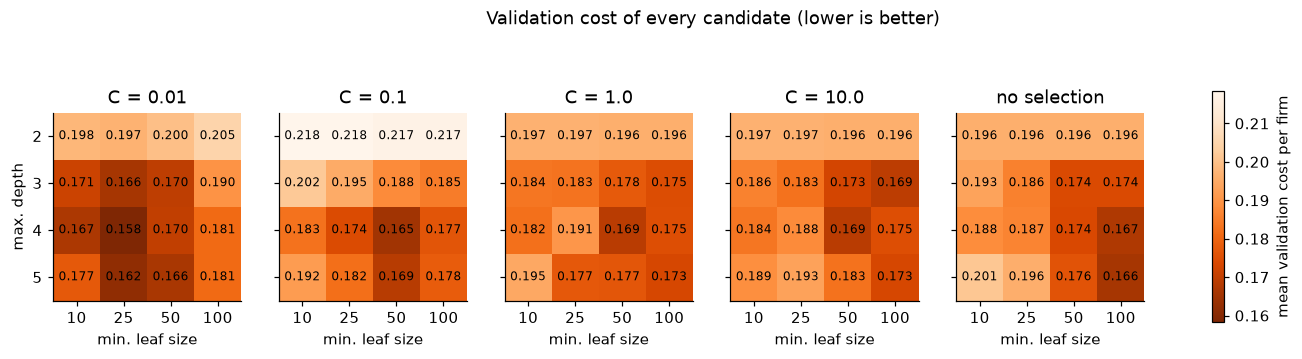

In [11]:
fig, axes = plt.subplots(1, len(SELECTION_OPTIONS), figsize=(16, 3.4), sharey=True)
vmin, vmax = summary["mean_cost"].min(), summary["mean_cost"].max()
for ax, option in zip(axes, SELECTION_OPTIONS):
    grid = summary[summary["selection"] == option].pivot(index="depth", columns="leaf", values="mean_cost")
    image = ax.imshow(grid, cmap="Oranges_r", vmin=vmin, vmax=vmax)
    for i in range(len(DEPTHS)):
        for j in range(len(LEAF_SIZES)):
            ax.text(j, i, f"{grid.iloc[i, j]:.3f}", ha="center", va="center", fontsize=8)
    ax.set(xticks=range(len(LEAF_SIZES)), xticklabels=LEAF_SIZES, xlabel="min. leaf size",
           yticks=range(len(DEPTHS)), yticklabels=DEPTHS,
           title=f"C = {option}" if option != "none" else "no selection")
axes[0].set_ylabel("max. depth")
fig.colorbar(image, ax=axes, shrink=0.8, label="mean validation cost per firm")
fig.suptitle("Validation cost of every candidate (lower is better)", y=1.02)
plt.show()

## 7. Step 4: choose the model
**The rule, fixed before looking at the result:** choose the candidate with the **lowest mean validation cost per firm**. "No selection" competes like any other option. If two candidates are tied (difference below $10^{-12}$), prefer the simpler one: fewer variables, then a shallower tree, then larger leaves.

This rule only uses development data. The test set is still untouched.

In [12]:
ranked = summary.sort_values(["mean_cost", "mean_variables", "depth", "leaf"],
                             ascending=[True, True, True, False]).reset_index(drop=True)
ranked["mean_cost"] = ranked["mean_cost"].round(12)        # ties below 1e-12 count as equal
ranked = ranked.sort_values(["mean_cost", "mean_variables", "depth", "leaf"],
                            ascending=[True, True, True, False]).reset_index(drop=True)
chosen = ranked.iloc[0]
best_without_selection = ranked[ranked["selection"] == "none"].iloc[0]

print("Chosen model:", f"selection C = {chosen['selection']},", f"depth {chosen['depth']},",
      f"leaf size {chosen['leaf']}")
comparison = pd.DataFrame({
    "chosen model": chosen,
    "best tree without selection": best_without_selection,
}).T[["selection", "depth", "leaf", "mean_variables", "mean_cost", "std_cost",
      "mean_recall", "mean_precision", "mean_flags"]]
comparison.loc["never flag"] = ["-", "-", "-", 0, never_flag.mean(), never_flag.std(), 0.0, np.nan, 0.0]
comparison

Chosen model: selection C = 0.01, depth 4, leaf size 25


,selection,depth,leaf,mean_variables,mean_cost,std_cost,mean_recall,mean_precision,mean_flags
chosen model,0.01,4,25,5.4,0.158387,0.013632,0.692698,0.276286,89.2
best tree without selection,none,5,100,92.0,0.165903,0.027703,0.69254,0.255857,97.4
never flag,-,-,-,0,0.32264,0.004099,0.0,NaN,0.0


**How sure can we be?** A difference between two candidates only means something if it is larger than the noise between folds. The next cell compares the chosen model with its closest rivals **fold by fold**: on how many of the five folds is the chosen model cheaper?

In [13]:
def fold_costs(row):
    match = ((cv_results["selection"] == row["selection"]) & (cv_results["depth"] == row["depth"])
             & (cv_results["leaf"] == row["leaf"]))
    return cv_results[match].set_index("fold")["cost per firm"]

chosen_costs = fold_costs(chosen)
per_fold = pd.DataFrame({"chosen model": chosen_costs,
                         "best without selection": fold_costs(best_without_selection),
                         "never flag": never_flag})
per_fold.loc["mean"] = per_fold.mean()
per_fold.round(3)

,chosen model,best without selection,never flag
1,0.151,0.157,0.330
2,0.153,0.143,0.321
3,0.182,0.144,0.321
4,0.149,0.209,0.321
5,0.156,0.177,0.321
mean,0.158,0.166,0.323


## 8. Step 5: freeze and refit on all development data
The choice is now frozen. Following the usual practice (*Statistical learning: empirical risk…*, p. 3: refitting after validation is allowed if an untouched test sample remains), we refit the chosen procedure on **all 5,455 development records**: cleanup, L1 selection with the chosen $C$ (if any), then the tree with the chosen depth and leaf size.

As `variable_selection.ipynb` notes (section 12), the same $C$ may keep a few more variables on the larger development set than in the folds.

In [14]:
if chosen["selection"] == "none":
    final_columns = structural_cleanup(development_X)
else:
    final_columns = select_variables(development_X, development_y, float(chosen["selection"]))

final_tree = DecisionTreeClassifier(max_depth=int(chosen["depth"]), min_samples_leaf=int(chosen["leaf"]),
                                    random_state=TREE_RANDOM_STATE)
final_tree.fit(development_X[final_columns], development_y)

used = pd.Series(final_tree.feature_importances_, index=final_columns)
used = used[used > 0].sort_values(ascending=False)
print(f"Variables given to the tree: {len(final_columns)}")
print(f"Variables the tree actually uses in its questions: {len(used)}")
used.rename("share of impurity reduction").round(3).to_frame()

Variables given to the tree: 6
Variables the tree actually uses in its questions: 5


,share of impurity reduction
Persistent EPS in the Last Four Seasons,0.614
Borrowing dependency,0.220
Net worth/Assets,0.067
Net Income to Total Assets,0.058
Debt ratio %,0.039


**Selected is not the same as used.** The selector hands the tree a list of variables. The tree is free to ignore some of them; the table lists only the variables it actually asks about, with their share of the total Gini reduction.

The next cell draws the tree. Each box shows the question (a firm that answers *yes* goes left), the share of all development firms that reach the box (`samples`) and the share of bankrupt firms among them (`value = [share not bankrupt, share bankrupt]`). A leaf is **orange when its bankrupt share is at least $1/11$**: these firms would be flagged. The thresholds are in the variables' original supplied units.

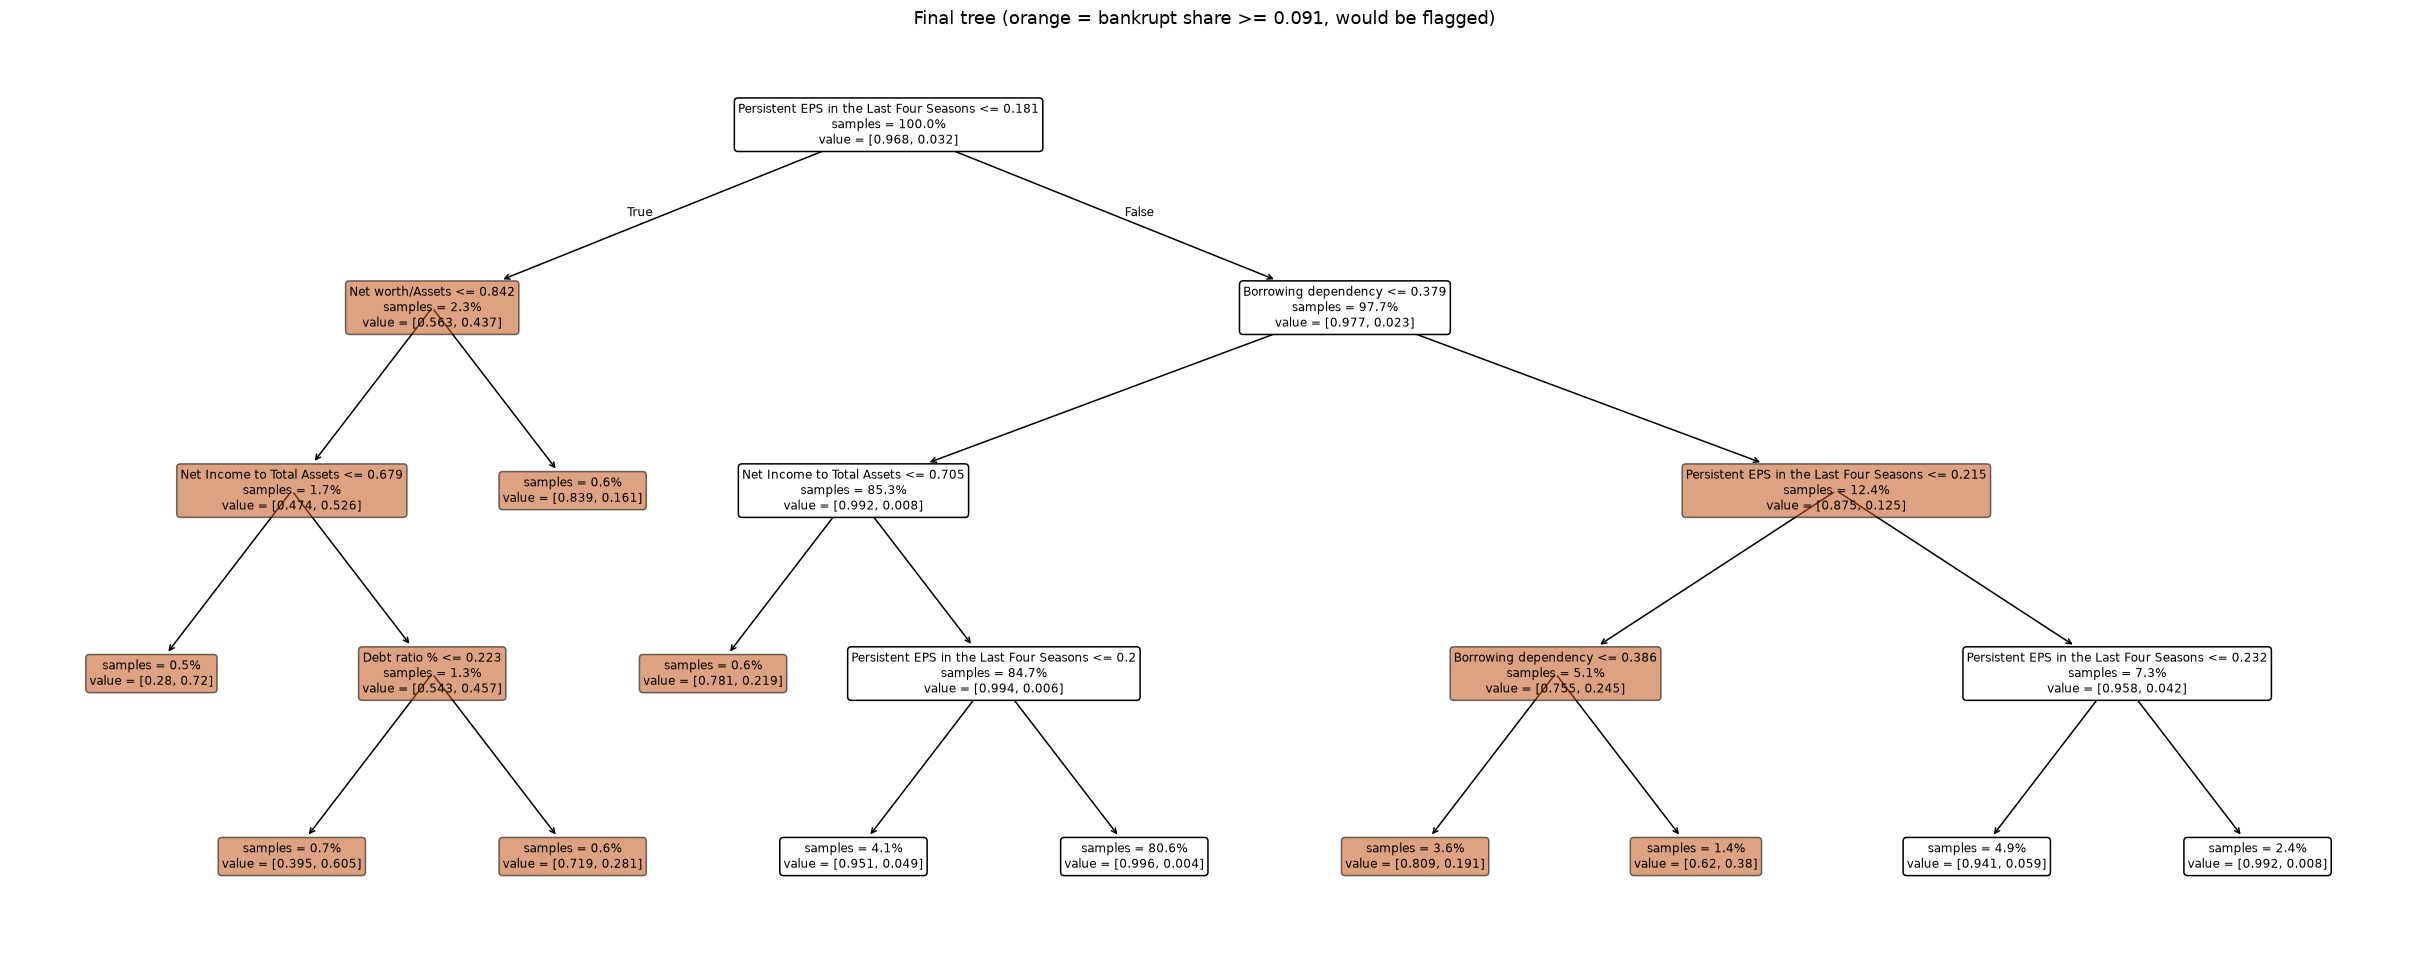

In [15]:
fig, ax = plt.subplots(figsize=(min(4 + 3 * 2 ** int(chosen["depth"]) / 2, 30), 2.2 * int(chosen["depth"]) + 2))
artists = plot_tree(final_tree, feature_names=final_columns,      # no class line: it would use a 0.5 cut-off
                    proportion=True, impurity=False, rounded=True, fontsize=8, ax=ax)
leaf_share = final_tree.tree_.value[:, 0, 1]                 # bankrupt share of each node
for artist, share in zip([a for a in artists if a.get_bbox_patch() is not None], leaf_share):
    artist.get_bbox_patch().set_facecolor(ORANGE if share >= THRESHOLD else "white")
    artist.get_bbox_patch().set_alpha(0.55 if share >= THRESHOLD else 1)
ax.set_title(f"Final tree (orange = bankrupt share >= {THRESHOLD:.3f}, would be flagged)")
plt.show()

## 9. Step 6: the one and only look at the test set
Now, and only now, we score the frozen model on the 1,364 test firms it has never seen. Whatever the result, we do not go back and change $C$, depth, leaf size or the threshold: that would turn the test set into a second validation set (*Statistical learning: empirical risk…*, p. 3).

For context, the table also shows never-flag and the best tree without selection, refitted the same way. They are reported, not used to change the choice.

In [16]:
reference_tree = DecisionTreeClassifier(max_depth=int(best_without_selection["depth"]),
                                        min_samples_leaf=int(best_without_selection["leaf"]),
                                        random_state=TREE_RANDOM_STATE)
reference_columns = structural_cleanup(development_X)
reference_tree.fit(development_X[reference_columns], development_y)

final_flags = (final_tree.predict_proba(test_X[final_columns])[:, 1] >= THRESHOLD).astype(int)
reference_flags = (reference_tree.predict_proba(test_X[reference_columns])[:, 1] >= THRESHOLD).astype(int)

test_results = pd.DataFrame.from_dict({
    "chosen model": evaluate(test_y, final_flags),
    "best tree without selection": evaluate(test_y, reference_flags),
    "never flag": evaluate(test_y, np.zeros(len(test_y), dtype=int)),
}, orient="index")
test_results.round(3)

,cost per firm,recall,precision,flags,missed bankruptcies
chosen model,0.149,0.705,0.298,104,13
best tree without selection,0.174,0.750,0.205,161,11
never flag,0.323,0.000,NaN,0,44


The confusion matrix below spells out the chosen model's 1,364 test decisions: bankruptcies caught and missed, and how many healthy firms were flagged needlessly.

In [17]:
confusion = pd.crosstab(pd.Series(test_y.to_numpy(), name="actual").map({0: "not bankrupt", 1: "bankrupt"}),
                        pd.Series(final_flags, name="decision").map({0: "no flag", 1: "flag"}))
confusion

decision,flag,no flag
actual,,
bankrupt,31,13
not bankrupt,73,1247


## 10. Save the results
The next cell writes two files to `outputs/model_selection/` for the report: every validation result (`cv_results.csv`, one row per candidate and fold) and the frozen choice with its test result (`final_model.json`).

In [18]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cv_results.to_csv(OUTPUT_DIR / "cv_results.csv", index=False)
final_model = {
    "selection_C": None if chosen["selection"] == "none" else float(chosen["selection"]),
    "max_depth": int(chosen["depth"]), "min_samples_leaf": int(chosen["leaf"]),
    "threshold": THRESHOLD, "costs": {"C_FP": C_FP, "C_FN": C_FN},
    "validation_mean_cost": float(chosen["mean_cost"]), "validation_std_cost": float(chosen["std_cost"]),
    "variables_given_to_tree": final_columns, "variables_used_by_tree": list(used.index),
    "test": {key: (None if pd.isna(value) else float(value))
             for key, value in test_results.loc["chosen model"].items()},
}
(OUTPUT_DIR / "final_model.json").write_text(json.dumps(final_model, indent=2))
print("Saved:", sorted(path.name for path in OUTPUT_DIR.iterdir()))

Saved: ['cv_results.csv', 'final_model.json']


## 11. Checks
The last code cell checks, with plain assertions, that the procedure respected its own rules: no test record was used for training or validation, every development record was validated exactly once, and every candidate was scored on all five folds.

In [19]:
assert set(development_ids).isdisjoint(test_ids)
assert len(fold_of) == len(development_ids) and set(fold_of) == set(FOLDS)
assert cv_results.groupby(["selection", "depth", "leaf"]).size().eq(len(FOLDS)).all()
assert len(summary) == len(SELECTION_OPTIONS) * len(DEPTHS) * len(LEAF_SIZES)
assert set(final_columns) <= set(predictor_names) and TARGET not in final_columns
print("All checks passed.")

All checks passed.


## 12. Findings from this run

**The chosen model.** L1 selection with $C = 0.01$, then a tree of depth 4 with at least 25 firms per leaf, flagging firms with an estimated bankruptcy probability $\geq 1/11$. In the final refit, the selector keeps 6 variables and the tree asks about 5 of them. *Persistent EPS in the Last Four Seasons* does most of the work (61% of the impurity reduction), followed by *Borrowing dependency*.

**Validation (development data, 5 folds).**

| Model | Mean cost per firm | Std. across folds | Variables |
|---|---|---|---|
| Chosen: $C = 0.01$, depth 4, leaf 25 | 0.158 | 0.014 | about 5 |
| Best tree without selection: depth 5, leaf 100 | 0.166 | 0.028 | 92 |
| Never flag | 0.323 | 0.004 | 0 |

- Both trees **halve the cost** of never flagging. That is the clear, robust result.
- Selection with $C = 0.01$ is slightly cheaper than no selection, but the difference (0.008) is **smaller than the fold-to-fold spread**, and the chosen model is cheaper in only 3 of the 5 folds. We therefore do **not** claim that selection improves prediction. What it does give is a model with about 5 variables instead of 92, that costs about the same and varies less between folds.
- The heatmap shows the usual trade-off: depth 2 is too simple for every selection option (about 0.20); very small leaves (10) are usually worse than leaves of 25–100, as expected from unstable leaf probabilities.

**Test (1,364 firms, used once).** The frozen model costs **0.149 per firm**, against 0.174 for the best tree without selection and 0.323 for never flagging. It catches **31 of 44** bankruptcies (recall 70%), misses 13 and flags 73 healthy firms (104 flags in total, 30% of them correct). The test cost is close to the validation estimate (0.158), so there is no sign that the choice was overly optimistic.

**Limitations.**
- With 44 bankruptcies in the test set, one more or one fewer missed bankruptcy changes the cost by about $10/1364 \approx 0.007$. The test comparison between the two trees rests on a few firms.
- The cost ratio $C_{FN}/C_{FP} = 10$ is an assumption (see `bankruptcy_prediction.ipynb`, 1.3). Another ratio changes the threshold and possibly the chosen model.
- The tree uses both *Debt ratio %* and *Net worth/Assets*, which are exact complements (they sum to 1, see `variable_selection.ipynb`). The selector does not remove this redundancy.
- The data have no dates and no company identifiers, so we cannot check how the model would perform on future years.